# 02 Image Preprocessing

## Project
Segmentation-Guided Explainable Hybrid Deep Learning Framework for Multi-Class Thoracic Disease Classification from Chest Radiographs

### Objective
This notebook performs preprocessing on the NIH Chest X-ray dataset.

Steps:
- Load Dataset
- Read Chest X-ray Images
- Resize Images (224×224)
- Apply CLAHE
- Normalize Pixel Values
- Perform Data Augmentation
- Save Processed Images

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

In [3]:
# Notebook Location
current_dir = os.getcwd()

# Project Root
project_root = os.path.abspath(os.path.join(current_dir, ".."))

# Dataset Folder
dataset_path = os.path.join(project_root, "dataset")

# Images Folder
image_folder = os.path.join(dataset_path, "images")

# Clean CSV
csv_file = os.path.join(dataset_path, "Data_Entry_2017_Clean.csv")

# Output Folder
processed_folder = os.path.join(dataset_path, "processed_images")

# Create output folder if it doesn't exist
os.makedirs(processed_folder, exist_ok=True)

print("Project Root :", project_root)
print("Dataset :", dataset_path)
print("Images :", image_folder)
print("Output :", processed_folder)

Project Root : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Dataset : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset
Images : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Output : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/processed_images


In [4]:
df = pd.read_csv(csv_file)

print("Dataset Loaded Successfully")
print("Shape :", df.shape)

df.head()

Dataset Loaded Successfully
Shape : (112120, 11)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143


In [5]:
# Development subset
df = df.sample(n=10000, random_state=42)

df.reset_index(drop=True, inplace=True)

print("Working Dataset Size :", len(df))

Working Dataset Size : 10000


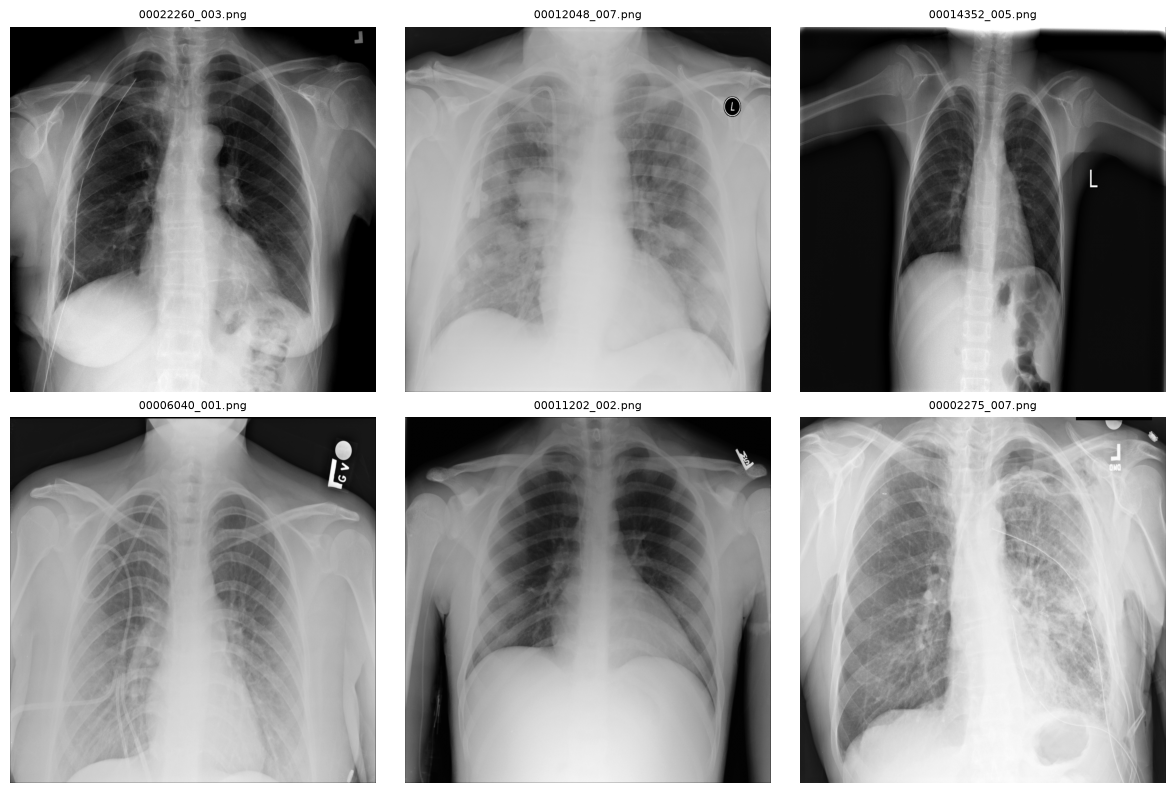

In [6]:
plt.figure(figsize=(12,8))

for i in range(6):

    img_name = df.loc[i, "Image Index"]

    img_path = os.path.join(image_folder, img_name)

    image = Image.open(img_path)

    plt.subplot(2,3,i+1)
    plt.imshow(image, cmap="gray")
    plt.title(img_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
IMG_SIZE = 224

def resize_image(image):

    resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

    return resized

In [8]:
img_name = df.loc[0, "Image Index"]

img_path = os.path.join(image_folder, img_name)

image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

print("Original Shape :", image.shape)

resized = resize_image(image)

print("Resized Shape :", resized.shape)

Original Shape : (1024, 1024)
Resized Shape : (224, 224)


In [9]:
# CLAHE Function

def apply_clahe(image):

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    enhanced = clahe.apply(image)

    return enhanced

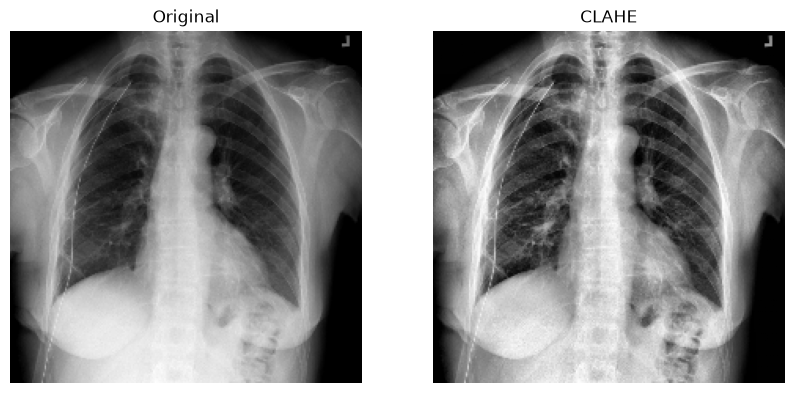

In [10]:
img_name = df.loc[0, "Image Index"]

img_path = os.path.join(image_folder, img_name)

image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

image = resize_image(image)

clahe_image = apply_clahe(image)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.show()

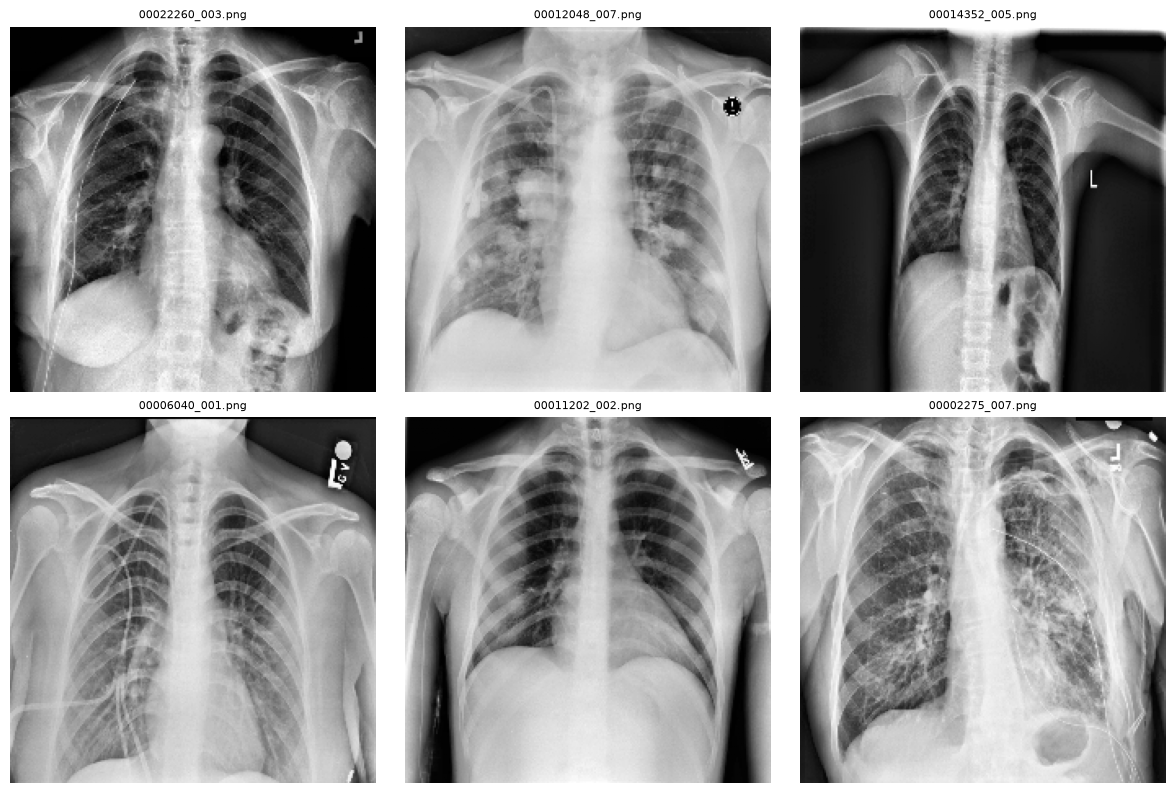

In [11]:
plt.figure(figsize=(12,8))

for i in range(6):

    img_name = df.loc[i, "Image Index"]

    img_path = os.path.join(image_folder, img_name)

    image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    image = resize_image(image)

    image = apply_clahe(image)

    plt.subplot(2,3,i+1)
    plt.imshow(image, cmap="gray")
    plt.title(img_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
img_name = df.loc[0, "Image Index"]

img_path = os.path.join(image_folder, img_name)

image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

image = resize_image(image)

image = apply_clahe(image)

normalized = image / 255.0

print("Minimum Pixel :", normalized.min())
print("Maximum Pixel :", normalized.max())

Minimum Pixel : 0.00784313725490196
Maximum Pixel : 0.984313725490196


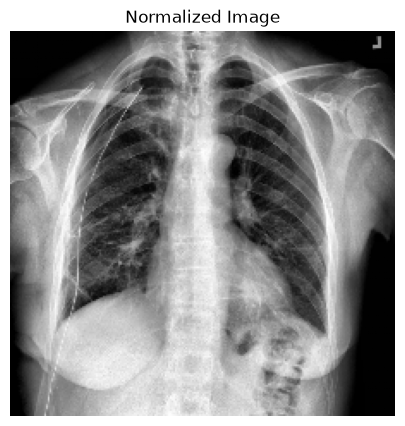

In [13]:
plt.figure(figsize=(5,5))

plt.imshow(normalized, cmap="gray")

plt.title("Normalized Image")

plt.axis("off")

plt.show()